# D-Wave CQM 与 QuantumBridge 门模型组合应用

真实股票历史回放 / Local execution, not hardware

## 真实数据与运行条件 / Real data & reproducibility

输入是 MSFT、IBM、SBUX、AAPL 的真实历史价格序列，不是生成的股票数据。
固定训练窗口为 **2015-01-02 至 2015-12-31（252 个交易日）**；组合验证使用 2016 年的独立留出窗口。
行情来源为 Plotly 公开数据仓库，数据字节以 SHA-256 验证，源提交和许可保存在包内。
原始复权方法未得到独立核验，因此价格、单股成本与损益均为**来源价格口径的历史回放**，不宣称经审计总收益或今天可以买卖的报价。

在本仓库安装 `pip install -e ".[finance-apps]"`，另装 `jupyter nbconvert matplotlib`，选择同一个 Python 内核。
本 Notebook 可在仓库根目录从上到下运行；不自动联网、不读取 token、不提交云任务。
包内数据支持离线重跑，改变参数后得到的是重新计算的模型结果。

所有金额均为 USD。定价是模型估值而非已观测期权成交价；历史风险与未来风险不等价。
读取、统计、分箱和一般状态制备都有经典成本；这里不假设免费 QRAM，也未建立端到端量子加速。

In [1]:
import sys, json, importlib.metadata, html
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from quantumbridge.finance import (
    load_stock_history, build_portfolio_cqm, solve_portfolio,
    pricing_case, risk_case, pennylane_qmc, hybrid_volatility_case,
)
from quantumbridge.finance.gate_exports import measurement_artifact
SHOTS, SEED = 1024, 20261102
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {p: importlib.metadata.version(p) for p in ['numpy','scipy','dimod','pennylane','torch']}
print('Python', sys.version.split()[0], '| installed dependencies:', versions)
print('Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice')

def table(rows):
    keys = list(rows[0])
    def cell(value):
        return html.escape(f'{value:.6g}' if isinstance(value, (float, np.floating)) else str(value))
    markup = '<div class="qb-table"><table><thead><tr>'+''.join('<th>'+cell(k)+'</th>' for k in keys)+'</tr></thead><tbody>'
    markup += ''.join('<tr>'+''.join('<td>'+cell(row[k])+'</td>' for k in keys)+'</tr>' for row in rows)
    display(HTML(markup+'</tbody></table></div>'))

def clean(value):
    if isinstance(value, dict):
        return {k: clean(v) for k,v in value.items() if k not in ('circuit','circuits','preparation')}
    if isinstance(value, (list,tuple)): return [clean(v) for v in value]
    if isinstance(value, np.generic): return value.item()
    return value

history = load_stock_history()
print(json.dumps(history.provenance, ensure_ascii=False, indent=2))
table([dict(symbol=s, first=history.dates[0], last=history.dates[-1], source_price_usd=float(history.prices[-1,i]))
       for i,s in enumerate(history.symbols)])

Python 3.12.6 | installed dependencies: {'numpy': '2.4.6', 'scipy': '1.18.1', 'dimod': '0.12.22', 'pennylane': '0.44.1', 'torch': '2.12.0'}
Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice
{
  "provider": "Plotly public datasets / stockdata.csv",
  "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a",
  "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b",
  "retrieved_date_utc": "2026-11-01",
  "observations": [
    "2007-01-03",
    "2016-03-01"
  ],
  "symbols": [
    "MSFT",
    "IBM",
    "SBUX",
    "AAPL",
    "GSPC"
  ],
  "currency": "USD",
  "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE",
  "license_file": "PLOTLY_LICENSE.txt",
  "license": "MIT as p

symbol,first,last,source_price_usd
MSFT,2015-01-02,2015-12-31,55.0845
IBM,2015-01-02,2015-12-31,136.228
SBUX,2015-01-02,2015-12-31,59.8345
AAPL,2015-01-02,2015-12-31,104.692


<a id="portfolio"></a>
## 1. CQM 投资组合：原理和约束

四个二元变量 xᵢ 表示是否持有一份来源价格单位；不是无限精度连续权重优化。
以 2015 年简单日收益估计年化 μ = 252 mean(r)，Σ = 252 cov(r)，权重 wᵢ = Pᵢ xᵢ / B。
目标为 **min λ wᵀΣw − μᵀw + fee Σxᵢ/B**。
预算约束为 Σ(Pᵢ + fee)xᵢ ≤ B；持仓数量 Σxᵢ = 2；MSFT、IBM、AAPL 的技术行业合计不超过 1。
SBUX 归入消费类。未投资现金按零利率计，单边交易费为每个买入 0.10 美元，不含退出费用。
收益年化与一次性费用的组合是示意目标，不是完备期限投资效用。

步骤：读取真实行情 → 仅训练期估计 μ/Σ → 建立真实 dimod CQM → ExactCQMSolver 枚举 →
独立检查全部 16 个位串的目标和约束 → 门电路 QAOA 对照 → 不参与训练的 2016 年价格回放。

**ExactCQMSolver 是经典 CPU 求解器，不是 D-Wave 量子硬件。**
CQM 对象可以交给另行配置的 Ocean 采样器，但这里没有创建或调用 Leap 客户端。

Actual CQM variables: ['MSFT', 'IBM', 'SBUX', 'AAPL']
Actual CQM constraints: ['cash_budget', 'holdings', 'technology_cap']
Annual covariance:
[[0.0798435  0.03287975 0.03727297 0.03960985]
 [0.03287975 0.04488173 0.02396492 0.02930591]
 [0.03727297 0.02396492 0.05106955 0.03149966]
 [0.03960985 0.02930591 0.03149966 0.07168232]]


bits,cost,feasible,objective,expected_return,volatility
0000,0,False,0,0,0
0001,104.792,False,0.0259773,0.0069428,0.127408
0010,59.9345,False,-0.108456,0.116466,0.0614624
0011,164.726,True,-0.0661715,0.123409,0.167822
0100,136.328,False,0.102577,-0.0677043,0.131184
0101,241.12,False,0.163097,-0.0607615,0.225196
0110,196.263,True,0.0102649,0.0487617,0.170466
0111,301.055,False,0.0870919,0.0557045,0.265926
1000,55.1845,False,-0.0491623,0.059628,0.07075
1001,159.976,False,-0.0043068,0.0665708,0.17515


CQM independently checked optimum: {'bits': '1010', 'cost': 115.118959, 'feasible': True, 'objective': -0.1474656757334908, 'expected_return': 0.17609403816142005, 'volatility': 0.1177269542603527}


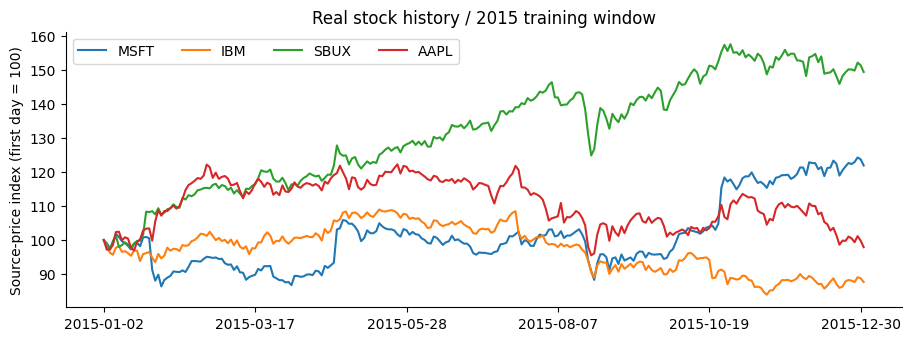

In [2]:
problem = build_portfolio_cqm(budget=220., risk_aversion=2., holdings=2, tech_cap=1, fee=.10)
print('Actual CQM variables:', list(problem.cqm.variables))
print('Actual CQM constraints:', list(problem.cqm.constraints))
print('Annual covariance:'); print(problem.covariance)
portfolio = solve_portfolio(problem, shots=SHOTS, seed=SEED, grid=13)
table(portfolio['candidates'])
print('CQM independently checked optimum:', portfolio['optimum'])
assert portfolio['status'] == 'solved'
assert all(row['cost'] <= 220+1e-9 for row in portfolio['candidates'] if row['feasible'])
fig, ax = plt.subplots(figsize=(9,3.3), layout='constrained')
ax.plot(history.dates, history.prices/history.prices[0]*100)
ax.set(xticks=np.arange(0,len(history.dates),50), ylabel='Source-price index (first day = 100)', title='Real stock history / 2015 training window')
ax.legend(history.symbols, ncol=4); plt.show()

## 2. 面向夸父门电路的 QAOA 对照

夸父是门模型平台，不能直接执行 D-Wave 的 CQM/退火 API。
这里把同一组 16 个候选目标加上显式不可行惩罚，惩罚系数取目标极差加 1，保证惩罚后的全局最小点可行。
预算不等式没有假装变成二次式：使用完整对角真值表及 Walsh 展开，可能包含高阶 Z 串。
每个 Z 串由 CX 奇偶校验链和 RZ 实现，混合层为 RX，实际电路为 4 量子比特、p=1。
本地 13×13 网格通过理想期望值选择角度，随后独立测量 1024 shots，保留不可行样本。
有限网格、浅层电路和模拟测量都不保证找到最优；经典搜索成本也计入实现步骤，没有量子加速声明。

Angles gamma/beta: 2.0943951023931953 2.8797932657906435
Encoding: Full diagonal feasibility penalty, including higher-order terms; not direct CQM/QUBO execution
Best observed feasible: {'bits': '1010', 'cost': 115.118959, 'feasible': True, 'objective': -0.1474656757334908, 'expected_return': 0.17609403816142005, 'volatility': 0.1177269542603527}
Observed objective gap: 0.0
Ideal feasible probability / sampled rate: 0.5215837857275011 0.5419921875


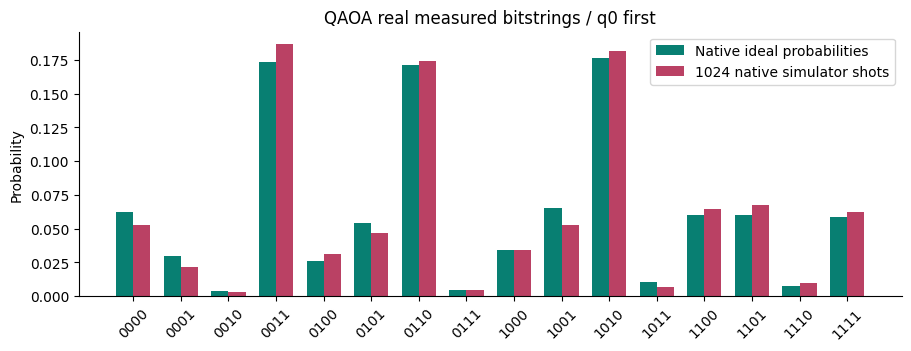

Measurement-only QASM2:
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
rz(-0.29024910670418602) q[3];
rz(0.74753555591025889) q[2];
cx q[2],q[3];
rz(0.22217999572926683) q[3];
cx q[2],q[3];
rz(-0.39008323331194111) q[1];
cx q[1],q[3];
rz(0.23395916285517659) q[3];
cx q[1],q[3];
cx q[1],q[2];
rz(0.22207440916533092) q[2];
cx q[1],q[2];
cx q[1],q[3];
cx q[2],q[3];
rz(-0.2116459031973216) q[3];
cx q[2],q[3];
cx q[1],q[3];
rz(-0.18005640632247771) q[0];
cx q[0],q[3];
rz(0.22384064270045906) q[3];
cx q[0],q[3];
cx q[0],q[2];
rz(0.21820435835455262) q[2];
cx q[0],q[2];
cx q[0],q[3];
cx q[2],q[3];
rz(-0.21164590319732149) q[3];
cx q[2],q[3];
cx q[0],q[3];
cx q[0],q[1];
rz(0.22481793107325318) q[1];
cx q[0],q[1];
cx q[0],q[3];
cx q[1],q[3];
rz(0.63493770959196505) q[3];
cx q[1],q[3];
cx q[0],q[3];
cx q[0],q[2];
cx q[1],q[2];
rz(-0.21164590319732182) q[2];
cx q[1],q[2];
cx q[0],q[2];
cx q[0],q[3];
cx q[1],q[3];
cx q[2],q[3];
rz(-0.63493770959196505) q[

In [3]:
q = portfolio['qaoa']
print('Angles gamma/beta:', q['gamma'], q['beta'])
print('Encoding:', q['encoding'])
print('Best observed feasible:', q['best_observed'])
print('Observed objective gap:', q['observed_gap'])
print('Ideal feasible probability / sampled rate:', q['feasible_probability'], q['observed_feasible_rate'])
labels = [r['bits'] for r in portfolio['candidates']]
x = np.arange(16)
fig, ax = plt.subplots(figsize=(9,3.4), layout='constrained')
ax.bar(x-.18, q['ideal_probabilities'], .36, label='Native ideal probabilities', color='#087f72')
ax.bar(x+.18, [q['counts'][s]/SHOTS for s in labels], .36, label='1024 native simulator shots', color='#ba4164')
ax.set(xticks=x,xticklabels=labels,ylabel='Probability',title='QAOA real measured bitstrings / q0 first')
ax.tick_params(axis='x', labelrotation=45); ax.legend(); plt.show()
qaoa_artifact = measurement_artifact(q['circuit'])
print('Measurement-only QASM2:'); print(qaoa_artifact['openqasm'])
print('SHA / gates:', qaoa_artifact['sha256'], qaoa_artifact['gates'])

<a id="constraints"></a>
## 3. 约束敏感性、中间结果和留出验证

下面改变预算，实际重复 CQM 检查。不可行结果保留为 `infeasible`，不偷偷删除约束。
最优模型组合固定于 2015-12-31，再用 2016 年行情回放；这不是在未来价格上选股票。
基准是四股等来源市值权重、现金零收益；基准未收取费用，不能视为完全匹配的可交易比较。

budget,status,feasible_count,optimum
100,infeasible,0,None
150,solved,1,1010
220,solved,3,1010


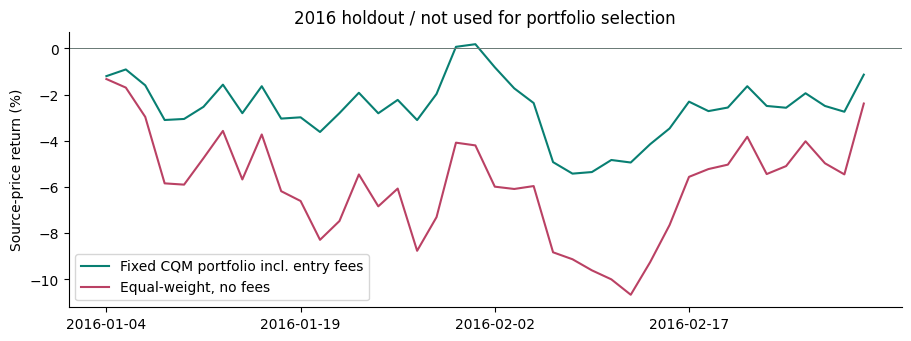

portfolio_holdout_return,equal_weight_return
-0.0113589,-0.0238569


In [4]:
sensitivity = []
for budget in (100., 150., 220.):
    solved = solve_portfolio(build_portfolio_cqm(budget=budget), shots=32, grid=3)
    sensitivity.append(dict(budget=budget, status=solved['status'],
                            feasible_count=sum(r['feasible'] for r in solved['candidates']),
                            optimum=None if solved['optimum'] is None else solved['optimum']['bits']))
table(sensitivity)
h = portfolio['holdout']
fig, ax = plt.subplots(figsize=(9,3.3), layout='constrained')
ax.plot(h['dates'], np.array(h['portfolio_return'])*100, label='Fixed CQM portfolio incl. entry fees', color='#087f72')
ax.plot(h['dates'], np.array(h['equal_weight_return'])*100, label='Equal-weight, no fees', color='#ba4164')
ax.axhline(0, color='#687874', linewidth=.7)
ax.set(xticks=np.arange(0,len(h['dates']),10), ylabel='Source-price return (%)',title='2016 holdout / not used for portfolio selection')
ax.legend(); plt.show()
table([dict(portfolio_holdout_return=h['portfolio_return'][-1], equal_weight_return=h['equal_weight_return'][-1])])
portfolio_evidence = dict(application='D-Wave CQM + native gate-model comparison', result=clean(portfolio),
                          budget_sensitivity=sensitivity, gate_artifact=qaoa_artifact, versions=versions,
                          hardware_jobs=0)

## 运行边界与夸父迁移 / Limits & Quafu path

本次 **0 个云端/真机任务**，不消耗原金融批次额度、不改写其回执。
现有 D3 审计仍是 NO_NEW_SUBMISSION_RECOMMENDED；物理布局、位序和精度验收没有被本批模拟解除。
Native QAOA/MLAE 电路已分解为基础门并导出可检查的 QASM2，量子比特不超过 4；
QASM2 不能保存全局相位，因此导出显式记录所移除的顶层相位，只承诺终端测量概率，不能作为保相位受控子程序复用。
PennyLane 矩阵参考电路是 9 比特模拟，未承诺可在旧的 6 比特真机额度下运行。
未来接真机前需要独立核验 gate basis、耦合图、深度、布局、位序和额外任务预算；
深 Grover 电路可能受噪声限制，不能把成功序列化称为硬件可用，更不能声称量子优势。

本次只有小规模金融研究应用，并不表示已完成 Qiskit + PennyLane 全部核心函数融合或生产金融系统。

### 练习与解答骨架
改变预算或执行价，只使用训练期重新计算；比较目标、可行性、离散化和有限 shots 误差。
不要用留出期选择预算、股票、角度或训练超参数。

### 一手来源
- [D-Wave ExactCQMSolver：经典本地枚举](https://docs.dwavequantum.com/en/latest/ocean/api_ref_dimod/sampler_composites.html)
- [D-Wave 官方组合优化示例：概念参考，未复制源码](https://github.com/dwave-examples/portfolio-optimization)
- [PennyLane QuantumMonteCarlo：模板和模拟器限制](https://docs.pennylane.ai/en/stable/code/api/pennylane.QuantumMonteCarlo.html)
- [真实行情源：固定提交](https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv)
- [行情源仓库 MIT 许可](https://github.com/plotly/datasets/blob/master/LICENSE)
- [原有夸父 D3 契约审计](finance_quafu_d3_client_contract.html)

QuantumBridge · 所属 相干(北京)科技有限公司

In [5]:
print('EVIDENCE_JSON='+json.dumps(portfolio_evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"application": "D-Wave CQM + native gate-model comparison", "result": {"backend": "dimod.ExactCQMSolver (classical CPU)", "dimod_version": "0.12.22", "hardware_jobs": 0, "source": {"provider": "Plotly public datasets / stockdata.csv", "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a", "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b", "retrieved_date_utc": "2026-11-01", "observations": ["2007-01-03", "2016-03-01"], "symbols": ["MSFT", "IBM", "SBUX", "AAPL", "GSPC"], "currency": "USD", "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE", "license_file": "PLOTLY_LICENSE.txt", "license": "MIT as published by the source repository; original upstream data methodology is not documented", "